## Лабораторная работа № 2 
## Машинное обучение на больших данных с использованием фреймворка Apache Spark и библиотеки SparkML

### Часть 1

В данной части работы рассмотрены:
* подготовка признаков для решения задачи **линейной регрессии**;
* создание и обучение модели линейной регрессии с подбором гиперпараметров;
* оценка качества модели и сравнение с baseline.

Датасет -- тот же, что подготовлен в лабораторной работе N 1: ДТП в США за 2016--2023 годы, 7 728 394 записи, очищенная таблица `otpushchennikov_us_accidents_processed`.

Подключаем необходимые библиотеки.

In [1]:
import os
import csv
import time
import numpy as np
import pandas as pd
from pyspark.sql import SparkSession, DataFrame
from pyspark import SparkConf
from pyspark.sql.functions import col, lit, coalesce, mean, sqrt, approx_count_distinct
from pyspark.sql.types import DoubleType
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    VectorAssembler,
    StringIndexer,
    OneHotEncoder,
    MinMaxScaler,
    Binarizer
)
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import CrossValidator, CrossValidatorModel, ParamGridBuilder
import seaborn as sns
import matplotlib.pyplot as plt

Сформируем объект конфигурации для `Apache Spark`, указав необходимые параметры.

In [2]:
def create_spark_configuration() -> SparkConf:
    """
    Создает и конфигурирует экземпляр SparkConf для приложения Spark.

    Returns:
        SparkConf: Настроенный экземпляр SparkConf.
    """
    # Получаем имя пользователя
    user_name = os.getenv("USER")

    conf = SparkConf()
    conf.setAppName("lab 2 US Accidents. Linear Regression")
    conf.setMaster("yarn")
    conf.set("spark.submit.deployMode", "client")
    conf.set("spark.executor.memory", "12g")
    conf.set("spark.executor.cores", "8")
    conf.set("spark.executor.instances", "2")
    conf.set("spark.driver.memory", "4g")
    conf.set("spark.driver.cores", "2")
    conf.set("spark.jars.packages",
             "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
    conf.set("spark.sql.extensions",
             "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
    conf.set("spark.sql.catalog.spark_catalog",
             "org.apache.iceberg.spark.SparkCatalog")
    conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
    conf.set("spark.sql.catalog.spark_catalog.warehouse",
             f"hdfs:///user/{user_name}/warehouse")
    conf.set("spark.sql.catalog.spark_catalog.io-impl",
             "org.apache.iceberg.hadoop.HadoopFileIO")

    return conf

Создаём сам объект конфигурации.

In [3]:
conf = create_spark_configuration()

Создаём и выводим на экран сессию `Apache Spark`. В процессе создания сессии происходит подключение к кластеру `Apache Hadoop`, что может занять некоторое время.

In [4]:
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user7/.ivy2/cache
The jars for the packages stored in: /home/user7/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-58f51755-dd5d-4a66-9f53-015832b85788;1.0
	confs: [default]


	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 574ms :: artifacts dl 20ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spark#spark-submit-parent-58f51755-dd5d-4a66-9f53-015832b85788
	confs: [default]
	0 artifacts copied, 1 already retrieved (0kB/24ms)


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/31 13:00:24 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


26/10/31 13:00:28 WARN Client: Neither spark.yarn.jars nor spark.yarn.archive is set, falling back to uploading libraries under SPARK_HOME.


26/10/31 13:00:49 WARN Client: Same path resource file:///home/user7/.ivy2/jars/org.apache.iceberg_iceberg-spark-runtime-3.5_2.12-1.6.0.jar added multiple times to distributed cache.


#### Загрузка датасета

Укажем базу данных, которая была создана в первой лабораторной работе.

In [5]:
database_name = "otpushchennikov_database"

Установим созданную базу данных как текущую.

In [6]:
spark.catalog.setCurrentDatabase(database_name)

Прочитаем таблицу с **предобработанным датасетом** и загрузим её в `Spark DataFrame`.

In [7]:
df = spark.table("otpushchennikov_us_accidents_processed")

Выведем прочитанную таблицу на экран.

In [8]:
df.show()

26/10/31 13:01:47 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+---------+--------+-------------------+-------------------+------------------+-----------+-------------------+----------------+--------------+-----+-------+----------+------------+--------------+-------------+-----------+------------+--------------+--------------+---------------+-----------------+-----------------+--------+--------+--------+-------+-------+-------+-----+--------------+--------------+--------------+-----------------+---------------------+------------------+-----+-----------+----+
|       ID|Severity|         Start_Time|           End_Time|         Start_Lat|  Start_Lng|       Distance(mi)|            City|        County|State|Zipcode|  Timezone|Airport_Code|Temperature(F)|Wind_Chill(F)|Humidity(%)|Pressure(in)|Visibility(mi)|Wind_Direction|Wind_Speed(mph)|Precipitation(in)|Weather_Condition|Crossing|Give_Way|Junction|No_Exit|Railway|Station| Stop|Traffic_Signal|Sunrise_Sunset|Civil_Twilight|Nautical_Twilight|Astronomical_Twilight|      Duration_min|Month|Day_Of_Week|Ho

Вспомним описание столбцов и их характеристики, установленные в первой лабораторной работе.

| Название столбца | Расшифровка | Тип признака и его характеристики |
| --- | --- | --- |
| `ID` | Идентификатор происшествия | категориальный, уникальный, в модели не используется |
| `Severity` | Тяжесть происшествия | количественный, дискретный, 1--4; целевая переменная части 2 |
| `Start_Time`, `End_Time` | Начало и конец происшествия | временные метки; в вектор признаков не входят, но из них получены `Duration_min`, `Month`, `Day_Of_Week`, `Hour` |
| `Duration_min` | Длительность происшествия, минуты | **целевая переменная части 1**, непрерывный, сверху обрезан до 2880 мин |
| `Start_Lat`, `Start_Lng` | Координаты начала | количественные, в модель не входят: их роль выполняет признак места |
| `Distance(mi)` | Расстояние до ближайшего перекрёстка | количественный, непрерывный, обрезан до 60 миль |
| `City`, `County`, `Zipcode`, `Timezone`, `Airport_Code` | Город, округ, почтовый индекс, часовой пояс, код аэропорта | категориальные; кардинальность измеряется ниже, в one-hot не попадают, если она велика |
| `State` | Штат | категориальный |
| `Temperature(F)`, `Wind_Chill(F)`, `Humidity(%)`, `Pressure(in)`, `Visibility(mi)`, `Wind_Speed(mph)` | Погодные показатели | количественные, пропуски заполнены медианами |
| `Precipitation(in)` | Осадки | количественный, пропуски заполнены нулём, поэтому распределение вырождено в нуле |
| `Wind_Direction`, `Weather_Condition` | Направление ветра, погодные условия | категориальные, приведены к 19 и 29 уровням |
| `Crossing`, `Give_Way`, `Junction`, `No_Exit`, `Railway`, `Station`, `Stop`, `Traffic_Signal` | Инфраструктура места происшествия | бинарные флаги, доли истинных значений от 0,25 % до 14,80 % |
| `Sunrise_Sunset` | Светлое или тёмное время суток | категориальный, 2 значения; `Civil_Twilight`, `Nautical_Twilight`, `Astronomical_Twilight` -- его производные, в конвейер не включены |
| `Month`, `Day_Of_Week`, `Hour` | Месяц, день недели, час начала | количественные дискретные, извлечены из `Start_Time` |

Вспомним схему данных.

In [9]:
df.printSchema()

root
 |-- ID: string (nullable = true)
 |-- Severity: integer (nullable = true)
 |-- Start_Time: timestamp (nullable = true)
 |-- End_Time: timestamp (nullable = true)
 |-- Start_Lat: double (nullable = true)
 |-- Start_Lng: double (nullable = true)
 |-- Distance(mi): double (nullable = true)
 |-- City: string (nullable = true)
 |-- County: string (nullable = true)
 |-- State: string (nullable = true)
 |-- Zipcode: string (nullable = true)
 |-- Timezone: string (nullable = true)
 |-- Airport_Code: string (nullable = true)
 |-- Temperature(F): float (nullable = true)
 |-- Wind_Chill(F): float (nullable = true)
 |-- Humidity(%): float (nullable = true)
 |-- Pressure(in): float (nullable = true)
 |-- Visibility(mi): float (nullable = true)
 |-- Wind_Direction: string (nullable = true)
 |-- Wind_Speed(mph): float (nullable = true)
 |-- Precipitation(in): float (nullable = true)
 |-- Weather_Condition: string (nullable = true)
 |-- Crossing: boolean (nullable = true)
 |-- Give_Way: boolean 

Вычислим количество строк в датафрейме.

In [10]:
df.count()

7728394

#### Постановка задачи линейной регрессии

Для датасета, заданного представленными колонками, требуется построить модель линейной регрессии для оценки **длительности происшествия** `Duration_min` (в минутах) по остальным признакам.

Для оценки качества обучения следует использовать метрики $RMSE$ и $R^2$; дополнительно рассчитаем $MAE$ и $RMSE$ тривиального предсказателя (константа -- медиана обучающей выборки), чтобы понять, извлекла ли модель из данных что-то полезное или повторяет «среднее по больнице».

Выбор мишени определяется результатами разведочного анализа из лабораторной работы N 1: `Duration_min` вычислен из `Start_Time` и `End_Time`, пропусков не содержит, ограничен сверху 2880 мин; линейная связь этого признака с остальными числовыми признаками слабая -- максимальный $|r|$ даёт `Distance(mi)` (0,122). Поэтому ожидания от линейной модели умеренные, и сравнение с baseline здесь обязательно.

#### Подготовка и кодирование признаков

Для корректной работы трансформеров приведём целевой признак, бинарные флаги и все количественные признаки к типу `DoubleType`. Две причины:
* бинарные флаги в очищенной таблице остаются столбцами `boolean` с допустимым `NULL`: отсутствующее значение трактуем как «признак не зафиксирован», то есть как `false` (0,0), иначе `VectorAssembler` вставит в вектор признаков `NaN`;
* метеорологические признаки в таблице Iceberg записаны как `FloatType` (4 байта), а трансформеры `SparkML` работают только с 64-битными вещественными значениями и на `FloatType` отвечают ошибкой `Data type FloatType is not supported`.

In [11]:
binary_flags = [
    "Crossing", "Give_Way", "Junction", "No_Exit",
    "Railway", "Station", "Stop", "Traffic_Signal"
]
float_features = [
    "Distance(mi)", "Temperature(F)", "Wind_Chill(F)", "Humidity(%)",
    "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)",
    "Month", "Day_Of_Week", "Hour"
]

df = df.withColumn("Duration_min", col("Duration_min").cast(DoubleType()))
for name in float_features:
    df = df.withColumn(name, col(name).cast(DoubleType()))
for flag in binary_flags:
    df = df.withColumn(
        flag,
        coalesce(col(flag).cast(DoubleType()), lit(0.0))
    )

Проверим, что у целевого признака нет пропусков: модель регрессии не работает с `NULL` в метке. Если такие строки найдутся, отсечем их.

In [12]:
null_label = df.filter(col("Duration_min").isNull()).count()
print(f"Строк без значения Duration_min: {null_label}")

if null_label > 0:
    df = df.filter(col("Duration_min").isNotNull())

print(f"Строк в работе: {df.count()}")

Строк без значения Duration_min: 0


Строк в работе: 7728394


Посмотрим сводную статистику целевого признака: медиану, верхние квантили и стандартное отклонение. Для тяжёлого правого хвоста среднее заметно больше медианы, и именно это ограничивает применимость линейной регрессии.

In [13]:
df.select(col("Duration_min").alias("value")).summary("50%", "90%", "99%").show()

+-------+------------------+
|summary|             value|
+-------+------------------+
|    50%| 74.83333587646484|
|    90%|245.13333129882812|
|    99%| 797.8499755859375|
+-------+------------------+



Проверим кардинальность категориальных столбцов до выбора способа кодировки: `one-hot` признак с тысячью уровней превратит вектор признаков в разреженную матрицу на десятки тысяч колонок, в которой линейная модель не обучается за разумное время. Оценку считаем `approx_count_distinct` за один проход по данным.

In [14]:
candidate_categorical = [
    "State", "Weather_Condition", "Wind_Direction", "Sunrise_Sunset",
    "Timezone", "Airport_Code", "County", "City", "Zipcode"
]

cardinality = df.agg(
    *[approx_count_distinct(col(name)).alias(name) for name in candidate_categorical]
).toPandas().T
cardinality.columns = ["число уровней"]
print(cardinality.sort_values("число уровней", ascending=False).to_string())

                   число уровней
Zipcode                    24842
City                       13769
County                      1926
Airport_Code                1909
State                         52
Weather_Condition             29
Wind_Direction                19
Timezone                       5
Sunrise_Sunset                 3


Отделим от датасета некоторую часть объёмом примерно 1000 строк, и сохраним её на диске как локальный `csv`-файл. Он понадобится в следующей лабораторной работе.

In [15]:
def save_sample_to_csv(data: DataFrame, file_path: str,
                       sample_size: int = 1000) -> DataFrame:
    """
    Сохраняет первые `sample_size` строк из DataFrame в CSV-файл на драйвере
    и возвращает DataFrame с оставшимися данными.

    Args:
        data (DataFrame): DataFrame, из которого нужно извлечь строки.
        file_path (str): Путь для сохранения CSV-файла.
        sample_size (int): Количество строк для сохранения
            (по умолчанию 1000).

    Returns:
        DataFrame: DataFrame с оставшимися данными.
    """
    # Определяем пропорции для разделения
    sample_fraction = sample_size / data.count()
    remaining_fraction = 1 - sample_fraction

    # Разделяем DataFrame на два непересекающихся набора данных
    sample_data, remaining_data = data.randomSplit(
        [sample_fraction, remaining_fraction]
    )

    # Сохраняем извлеченные строки в CSV-файл на драйвере
    try:
        with open(file_path, mode="w", newline="") as file:
            writer = csv.writer(file)

            # Записываем заголовок
            writer.writerow(data.columns)

            # Записываем строки
            for row in sample_data.take(sample_size):
                writer.writerow(row)
        print(f"Файл \"{file_path}\" с данными успешно создан.")

    except Exception as e:
        print(f"Ошибка при записи файла: {e}")

    return remaining_data

Определяем путь для сохранения `csv`-файла.

In [16]:
path = "us_accidents_sample.csv"

df = save_sample_to_csv(data=df, file_path=path, sample_size=1000)

Файл "us_accidents_sample.csv" с данными успешно создан.


Оцениваем, сколько строк в датасете осталось.

In [17]:
df.count()

7727405

Разделим датасет на обучающую и тестовую выборки.

In [18]:
train_df, test_df = df.randomSplit([0.8, 0.2])

In [19]:
print(f"Train dataset size: {train_df.count()}")
print(f"Test  dataset size: {test_df.count()}")

Train dataset size: 6180705


Test  dataset size: 1546700


Признаки для модели.

* **Категориальные** признаки с небольшой кардинальностью (штат, погодные условия, направление ветра, время суток) закодируем `one-hot`-кодировкой: линейной модели нужен числовой вектор, а порядок индексов у таких категорий смысла не имеет.
* **Бинарные** признаки приведены к единице и нулю, в дополнительном кодировании не нуждаются.
* **Количественные** признаки нормализуем `MinMaxScaler`-ом: у них разный масштаб (влажность в процентах против давления в дюймах), а $L_1$/$L_2$-штраф на коэффициенты без приведения масштаба наказывал бы признаки произвольно.
* `Precipitation(in)` после заполнения пропусков нулём сосредоточен в нуле, то есть ближе к бинарному «дождь / нет дождя». **Бинаризуем** его по порогу 0,1 дюйма.

В модель не идут: `ID` (уникальный в каждой строке), координаты (их роль выполняет штат), `City`, `County`, `Zipcode`, `Timezone`, `Airport_Code` (см. замер кардинальности выше), `Severity` (это мишень второй части, а не предиктор длительности) и `Start_Time` / `End_Time` (из них уже извлечены `Month`, `Day_Of_Week`, `Hour`, а `Duration_min` является меткой).

In [20]:
categorical_features = ["State", "Weather_Condition",
                      "Wind_Direction", "Sunrise_Sunset"]
binary_features = [
    "Crossing", "Give_Way", "Junction", "No_Exit",
    "Railway", "Station", "Stop", "Traffic_Signal"
]
numeric_features = [
    "Distance(mi)", "Temperature(F)", "Wind_Chill(F)", "Humidity(%)",
    "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)",
    "Month", "Day_Of_Week", "Hour"
]
binarizable_feature = "Precipitation(in)"
label_col = "Duration_min"
threshold = 0.1

Проверим утверждение о «бинарности» осадков: какая доля записей превышает выбранный порог.

In [21]:
total_rows = df.count()
wet_rows = df.filter(col(binarizable_feature) > threshold).count()
print(f"Записей с осадками > {threshold} in: {wet_rows} "
      f"({100.0 * wet_rows / total_rows:.2f} %)")

Записей с осадками > 0.1 in: 117258 (1.52 %)


Создадим конвейер обработки данных, включающий модель линейной регрессии.

In [22]:
def create_pipeline(categorical_features: list[str], numeric_features: list[str],
                    binary_features: list[str], binarized_col: str,
                    threshold: float, label_col: str, max_iter: int) -> Pipeline:
    """
    Создает конвейер подготовки признаков и модель линейной регрессии.

    Args:
        categorical_features: Список категориальных признаков.
        numeric_features: Список количественных признаков.
        binary_features: Список бинарных признаков.
        binarized_col: Название бинаризуемого признака.
        threshold: Порог бинаризации.
        label_col: Название столбца с целевой переменной.
        max_iter: Максимальное количество итераций для модели.

    Returns:
        Pipeline: Конвейер подготовки признаков и обучения модели.
    """
    # Формируем названия колонок для преобразованных признаков
    indexed_categorical_features = [f"{feature}_index" for feature in categorical_features]
    onehot_categorical_features = [f"{feature}_ohe" for feature in categorical_features]

    # Выполняем преобразования данных
    string_indexer = StringIndexer(inputCols=categorical_features,
                                   outputCols=indexed_categorical_features,
                                   handleInvalid="keep")
    onehot_encoder = OneHotEncoder(inputCols=indexed_categorical_features,
                                   outputCols=onehot_categorical_features,
                                   dropLast=True,
                                   handleInvalid="keep")
    vector_num_assembler = VectorAssembler(inputCols=numeric_features,
                                           outputCol="numeric_vector",
                                           handleInvalid="keep")
    numeric_scaler = MinMaxScaler(inputCol="numeric_vector",
                                  outputCol="numeric_vector_scaled")
    binarizer = Binarizer(inputCol=binarized_col,
                          outputCol="precipitation_binary",
                          threshold=threshold)
    vector_all_assembler = VectorAssembler(
        inputCols=(onehot_categorical_features + binary_features +
                   ["numeric_vector_scaled", "precipitation_binary"]),
        outputCol="features",
        handleInvalid="keep"
    )

    # Создаем модель линейной регрессии
    linear_regression = LinearRegression(featuresCol="features",
                                         labelCol=label_col,
                                         predictionCol="prediction",
                                         standardization=False,
                                         maxIter=max_iter)

    # Создаем конвейер
    pipeline = Pipeline(stages=[
        string_indexer, onehot_encoder, vector_num_assembler,
        numeric_scaler, binarizer, vector_all_assembler,
        linear_regression
    ])

    return pipeline

In [23]:
pipeline = create_pipeline(categorical_features=categorical_features,
                           numeric_features=numeric_features,
                           binary_features=binary_features,
                           binarized_col=binarizable_feature,
                           threshold=threshold,
                           label_col=label_col,
                           max_iter=15)

#### Обучение модели

Выполним **подбор гиперпараметров** модели линейной регрессии с помощью кросс-валидации на сетке.

Модель обучается методом L-BFGS; `regParam` задаёт силу регуляризации, `elasticNetParam` -- баланс между $L_2$ (гребневая регрессия) и $L_1$ (лассо). Сетка из трёх значений силы штрафа и трёх значений его типа даёт девять комбинаций. Создаем сетку параметров, получив объект `LinearRegression` из конвейера.

In [24]:
param_grid = ParamGridBuilder() \
    .addGrid(pipeline.getStages()[-1].regParam, [0.01, 0.1, 1.0]) \
    .addGrid(pipeline.getStages()[-1].elasticNetParam, [0.0, 0.5, 1.0]) \
    .build()
print(f"Число комбинаций параметров: {len(param_grid)}")

Число комбинаций параметров: 9


Создаем экземпляр `RegressionEvaluator` для оценки модели.

In [25]:
cv_evaluator = RegressionEvaluator(labelCol=label_col,
                                   predictionCol="prediction",
                                   metricName="rmse")

Кешируем обучающую и тестовую выборки: кросс-валидация прогоняет конвейер много раз, и без кеша каждый прогон перечитывал бы таблицу Iceberg и перестраивал выборку.

In [26]:
train_df = train_df.cache()
test_df = test_df.cache()
print(f"Train rows cached: {train_df.count()}")

Train rows cached: 6180705


Оценка стоимости подбора. Перед запуском кросс-валидации измеряем, сколько стоит одно обучение конвейера на всей обучающей выборке, и умножаем на число обучений (`число комбинаций × число фолдов`): эта цифра определяет, какую сетку параметров можно позволить себе на кластере.

In [27]:
t0 = time.time()
single_pipeline_model = pipeline.fit(train_df)
one_fit_seconds = time.time() - t0

n_fits = len(param_grid) * 5
print(f"Время одного обучения конвейера: {one_fit_seconds:.1f} сек")
print(f"Число обучений в кросс-валидации: {n_fits}")
print(f"Оценка времени подбора: {one_fit_seconds * n_fits / 60:.1f} мин")

26/10/31 13:06:01 WARN Instrumentation: [005683a4] regParam is zero, which might cause numerical instability and overfitting.


26/10/31 13:06:37 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS


26/10/31 13:06:37 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK
26/10/31 13:06:37 WARN Instrumentation: [005683a4] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.


Время одного обучения конвейера: 108.8 сек
Число обучений в кросс-валидации: 45
Оценка времени подбора: 81.6 мин


Создаем объект `CrossValidator`. По замеру выше видно, что девять комбинаций параметров на пяти фолдах дают сорок пять обучений конвейера, и именно подбор является самым долгим этапом работы.

In [28]:
cross_validator = CrossValidator(estimator=pipeline,
                                 estimatorParamMaps=param_grid,
                                 evaluator=cv_evaluator,
                                 numFolds=5)

Обучаем модель конвейера с использованием кросс-валидации.

In [29]:
cv_model = cross_validator.fit(train_df)

26/10/31 13:08:25 WARN Instrumentation: [45eb7e59] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.


26/10/31 13:12:04 WARN Instrumentation: [f5fa5cef] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.


26/10/31 13:15:31 WARN Instrumentation: [880c3329] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.


26/10/31 13:19:27 WARN Instrumentation: [7f4e8d59] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.


26/10/31 13:23:03 WARN Instrumentation: [27948437] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.


26/10/31 13:26:26 WARN Instrumentation: [c8f99f8f] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.


... (6 outputs left out)

26/10/31 13:51:52 WARN Instrumentation: [355c6327] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.


26/10/31 13:55:24 WARN Instrumentation: [03cceca3] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.


26/10/31 13:58:46 WARN Instrumentation: [03dababa] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.


26/10/31 14:02:18 WARN Instrumentation: [d3a9a39a] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.


Выведем параметры **лучшей** модели, определенной в ходе кросс-валидации.

In [30]:
def get_best_model_params(cv_model: CrossValidatorModel) -> dict[str, float]:
    """
    Получает параметры лучшей модели из объекта CrossValidatorModel.

    Args:
        cv_model (CrossValidatorModel): Объект CrossValidatorModel,
            содержащий лучшую модель.

    Returns:
        dict[str, float]: Параметры лучшей модели.
    """
    best_model = cv_model.bestModel
    best_params = {
        "regParam": best_model.stages[-1].getRegParam(),
        "elasticNetParam": best_model.stages[-1].getElasticNetParam(),
        "maxIter": best_model.stages[-1].getMaxIter()
    }
    return best_params

In [31]:
for key, value in get_best_model_params(cv_model=cv_model).items():
    print(f"{key}: {value}")

regParam: 0.01
elasticNetParam: 0.0
maxIter: 15


Посмотрим, как кросс-валидация оценила сами комбинации: это показывает, работает ли регуляризация вообще и в какую сторону.

In [32]:
cv_scores = pd.DataFrame({
    "regParam": [grid[pipeline.getStages()[-1].regParam] for grid in param_grid],
    "elasticNetParam": [grid[pipeline.getStages()[-1].elasticNetParam]
                        for grid in param_grid],
    "cv_rmse": cv_model.avgMetrics,
})
print(cv_scores.sort_values("cv_rmse").to_string(index=False))

 regParam  elasticNetParam    cv_rmse
     0.01              0.0 178.299641
     0.01              0.5 178.300651
     0.01              1.0 178.305150
     0.10              0.0 178.488510
     0.10              1.0 178.491100
     0.10              0.5 178.501893
     1.00              0.0 179.297736
     1.00              0.5 180.129787
     1.00              1.0 180.615951


Проверим размерность признакового вектора и структуру коэффициентов: `one-hot` расширил категориальные признаки, а регуляризация обнулила часть коэффициентов -- по числу обнулённых видно, работает ли $L_1$-компонента как отбор признаков.

In [33]:
lr_model = cv_model.bestModel.stages[-1]
coefficients = np.array(lr_model.coefficients.toArray())

print(f"Размерность вектора признаков: {coefficients.size}")
print(f"Обнулено регуляризацией коэффициентов: {(coefficients == 0).sum()}")
print(f"Наибольший по модулю коэффициент: {np.abs(coefficients).max():.4f}")
print(f"Свободный член (intercept): {lr_model.intercept:.2f}")

Размерность вектора признаков: 123
Обнулено регуляризацией коэффициентов: 4
Наибольший по модулю коэффициент: 647.7537
Свободный член (intercept): 159.90


#### Анализ процесса обучения

Визуализируем изменение значения функции ошибки по итерациям L-BFGS и посмотрим метрики, рассчитанные на **обучающей** выборке.

In [34]:
def plot_training_summary(cv_model: CrossValidatorModel) -> None:
    """
    Отображает график зависимости значения ошибки от номера итерации на
    обучающей выборке, а также значения метрик RMSE и R^2.

    Args:
        cv_model (CrossValidatorModel): Обученная модель с использованием
            кросс-валидации.
    """
    # Получаем лучшую модель
    best_model = cv_model.bestModel

    # Получаем информацию о процессе обучения
    training_summary = best_model.stages[-1].summary

    # Получаем значения ошибки для каждой итерации
    objective_history = training_summary.objectiveHistory

    # Строим график зависимости значения ошибки от номера итерации
    plt.figure(figsize=(10, 6))
    sns.lineplot(x=range(len(objective_history)),
                 y=objective_history,
                 marker='o')
    plt.xlabel('Итерация')
    plt.ylabel('Ошибка')
    plt.title("Зависимость значения функции ошибки от номера итерации")

    # Получаем значения метрик
    rmse = training_summary.rootMeanSquaredError
    r2 = training_summary.r2

    # Добавляем значения метрик на график
    plt.text(0.95, 0.95, f"RMSE: {rmse:.2f}\nR^2: {r2:.4f}",
             transform=plt.gca().transAxes, ha='right', va='top',
             bbox=dict(facecolor='white', alpha=0.8), zorder=5)
    plt.grid()

    plt.show()

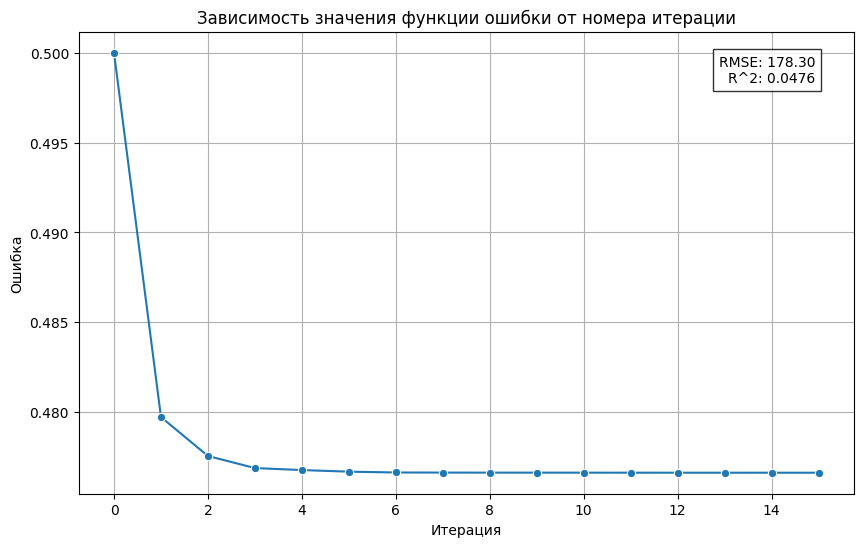

In [35]:
plot_training_summary(cv_model)

#### Проверка обобщающей способности модели

Выполним предсказания на тестовой выборке.

Перегруппируем колонки датафрейма, переставив столбец с целевым признаком и предсказание в конец, чтобы значения было удобно сравнивать.

In [36]:
# Получаем датасет предсказаний
test_df_predictions = cv_model.transform(test_df)

# Извлекаем список колонок, устанавливаем метку и предсказание на последнее место
right_columns_order = test_df_predictions.columns
right_columns_order.remove(label_col)
right_columns_order.append(label_col)
right_columns_order.remove("prediction")
right_columns_order.append("prediction")

# Изменяем последовательность колонок и выводим датафрейм
test_df_predictions = test_df_predictions.select(*right_columns_order)
test_df_predictions.show()

+---------+--------+-------------------+-------------------+------------------+-------------------+-------------------+-------------+--------------+-----+-------+----------+------------+------------------+-------------+-----------+------------------+--------------+--------------+------------------+--------------------+-----------------+--------+--------+--------+-------+-------+-------+----+--------------+--------------+--------------+-----------------+---------------------+-----+-----------+----+-----------+-----------------------+--------------------+--------------------+---------------+---------------------+------------------+------------------+--------------------+---------------------+--------------------+--------------------+------------+------------------+
|       ID|Severity|         Start_Time|           End_Time|         Start_Lat|          Start_Lng|       Distance(mi)|         City|        County|State|Zipcode|  Timezone|Airport_Code|    Temperature(F)|Wind_Chill(F)|Humidit

Создадим функцию оценки модели: расчета метрик для некоторого датасета, как правило, тестового.

In [37]:
def evaluate_model(data: DataFrame, metric_name: str) -> float:
    """
    Оценивает модель с использованием указанной метрики.

    Args:
        data (DataFrame): DataFrame, содержащий предсказания и фактические метки.
        metric_name (str): Название метрики для оценки
            (например, "rmse", "r2", "mae").

    Returns:
        float: Значение указанной метрики.
    """
    evaluator = RegressionEvaluator(labelCol=label_col,
                                    predictionCol="prediction",
                                    metricName=metric_name)
    metric_value = evaluator.evaluate(data)
    return metric_value

Оценим модель на тестовой выборке.

In [38]:
test_rmse = evaluate_model(test_df_predictions, "rmse")
test_r2 = evaluate_model(test_df_predictions, "r2")
test_mae = evaluate_model(test_df_predictions, "mae")

print(f"RMSE on test data: {test_rmse:.2f}")
print(f"R^2  on test data: {test_r2:.4f}")
print(f"MAE  on test data: {test_mae:.2f}")

RMSE on test data: 178.54
R^2  on test data: 0.0472
MAE  on test data: 85.00


Сравним результат с **baseline** -- тривиальным предсказателем, который выдаёт константу (медиану длительности по обучающей выборке) для любой записи. У такой модели $R^2$ около нуля, поэтому превышение её уровня и есть признак того, что конвейер извлек из данных что-то полезное.

In [39]:
median_duration = train_df.approxQuantile(label_col, [0.5], 0.001)[0]
print(f"Медиана Duration_min в обучающей выборке: {median_duration:.2f} мин")

baseline_rmse = (
    test_df
    .withColumn("residual", col(label_col) - median_duration)
    .select(sqrt(mean(col("residual") * col("residual"))).alias("rmse"))
    .collect()[0]["rmse"]
)
print(f"Baseline RMSE (константа = медиана): {baseline_rmse:.2f}")
print(f"Изменение RMSE относительно baseline: "
      f"{100.0 * (test_rmse - baseline_rmse) / baseline_rmse:.2f} %")

Медиана Duration_min в обучающей выборке: 74.85 мин


Baseline RMSE (константа = медиана): 187.65
Изменение RMSE относительно baseline: -4.85 %


Посмотрим, как распределена ошибка по уровням длительности. Средняя метрика скрывает главное: модель может хорошо «ловить» типичные короткие происшествия и систематически занижать затяжные. Для этого разобьем тестовую выборку на десять групп по истинной длительности и сравним среднее предсказание со средним фактом.

In [40]:
predictions_pandas = (
    test_df_predictions
    .sample(withReplacement=False, fraction=0.02, seed=17)
    .select(label_col, "prediction")
    .toPandas()
)
predictions_pandas["bucket"] = pd.qcut(predictions_pandas[label_col],
                                       q=10,
                                       labels=False,
                                       duplicates="drop")

bucketed = (
    predictions_pandas
    .groupby("bucket")
    .agg(actual=(label_col, "mean"),
         predicted=("prediction", "mean"),
         n=(label_col, "size"))
)
print(bucketed.round(2).to_string())

        actual  predicted     n
bucket                         
0        25.73     116.05  3181
1        29.68      99.84  3237
2        34.66     104.84  2908
3        46.79     104.50  3093
4        63.02     108.81  3106
5        77.26     117.98  3102
6        95.05     121.86  3105
7       125.15     124.64  3104
8       175.16     136.05  3122
9       481.05     130.23  3087


#### Сохранение модели

Зададим директорию студента в `HDFS`, в которой будет сохранена обученная модель.

In [41]:
student_hdfs_folder = "otpushchennikov_directory"

In [42]:
# Получаем имя пользователя
user_name = os.getenv("USER")

# Путь модели в HDFS
model_hdfs_path = f"hdfs:///user/{user_name}/{student_hdfs_folder}/models/lab2-lr-duration-model"

# Сохраняем модель конвейера в HDFS
try:
    cv_model.bestModel.save(model_hdfs_path)
    print(f"Модель успешно сохранена в \"{model_hdfs_path}\"")
except Exception as e:
    print(f"Ошибка при сохранении модели: {e}")

Модель успешно сохранена в "hdfs:///user/user7/otpushchennikov_directory/models/lab2-lr-duration-model"


#### Выводы по части 1

**Подбор параметров.** Сетка из 9 комбинаций при пяти фолдах дала 45 обучений конвейера. Одно «холодное» обучение заняло 108.8 сек, отсюда и оценка в 81.6 мин; фактически подбор занял около 56 мин (с 13:06 до 14:02 по отметкам в журнале `Spark`), то есть в среднем 75 сек на обучение, -- быстрее оценки, потому что обучающая выборка к этому моменту уже лежала в кеше и повторы конвейера не перечитывали Iceberg-таблицу.

Победил минимальный штраф: `regParam = 0.01`, `elasticNetParam = 0.0` (чистый гребень), $CV\ RMSE = 178.30$. Регуляризация этой модели не нужна: 6 180 705 обучающих строк против 123 признаков -- примерно 50 000 наблюдений на один параметр, переобучиться линейная модель здесь физически не может, а рост штрафа только портит решение: $CV\ RMSE$ монотонно ухудшается с 178.30 при `regParam = 0.01` до 180.62 при `regParam = 1.0`. Обнулено регуляризацией оказалось 4 коэффициента из 123, наибольший по модулю -- 647.75, свободный член 159.90. От 16 обучений решатель `Cholesky` сообщал о вырожденной матрице Грама и переключался на `Quasi-Newton`. `One-Hot`-кодирование 52 штатов вместе с сильно коррелированными `Temperature(F)` и `Wind_Chill(F)` даёт ранг меньше размерности вектора, поэтому в конвейере и оставлены малый штраф и `standardization = False`.

**Качество.** На тестовой выборке $RMSE = 178.54$ -- практически совпадает с $CV\ RMSE = 178.30$, значит подбор не переоптимизирован под фолды. При этом $R^2 = 0.0472$, а тривиальный предсказатель-константа (медиана 74.85 мин) даёт $RMSE = 187.65$: модель улучшает baseline всего на 4.85 %. Объяснение -- сильно скошенное правое распределение мишени: медиана 74.8 мин, 90-й процентиль 245.1 мин, 99-й 797.8 мин, и $RMSE$ формируется тяжёлым хвостом; $MAE = 85.00$ при медиане около 75 показывает то же самое.

**Главная находка -- систематическое усреднение.** В разбивке по декалям истинной длительности все средние предсказания модели укладываются в узкий диапазон 100--137 мин, тогда как факты меняются от 25.7 до 481.1 мин: короткие происшествия завышены примерно в 4.5 раза, затяжные занижены примерно в 3.7 раза. Это регрессия к среднему, неотъемлемое свойство линейной модели на тяжёлых хвостах: минимум среднеквадратичной ошибки она находит около условного среднего, а условное среднее здесь почти не зависит от признаков.

**Итог.** Линейная регрессия пригодна как baseline и как способ проверить гипотезу о слабой линейной связи длительности с признаками -- гипотеза подтвердилась ($R^2$ около 5 %). Для практического предсказания `Duration_min` её брать нельзя; нужны нелинейные модели (деревья, градиентный бустинг) или преобразование мишени (`log`) с последующим возвратом обратным преобразованием. Задача классификации тяжести в части 2, наоборот, обучается хорошо, что видно по $AUC\ ROC$ около 0.80.

Не забываем завершать `Spark`-сессию.

In [43]:
spark.catalog.clearCache()
spark.stop()